# Sex prediction from rPPG, Week 10: is it the pulse or the face? (MCD-rPPG)

**Where Week 9 left off.** The rPPG-only fusion reached AUC 0.824 and 78.1% accuracy. Four signs suggested part of it may be facial appearance rather than the heartbeat:
- the rPPG CNN (0.816) beat the contact-PPG CNN (0.796), which measures the pulse directly;
- cheeks alone scored 0.807, the forehead 0.670;
- the gain came from adding CHROM and green, which react more to skin and texture;
- the averaged rPPG beat barely matched the contact beat (correlation 0.28, another person 0.26).

**What this notebook does**
1. **Splits every rPPG signal into two parts** with a time-frequency mask that follows the heart rate over time:
   - *pulse-locked*: only the heart rate and its harmonics (up to 8 Hz);
   - *pulse removed*: everything else in 0.5–8 Hz.
2. **Phase-scrambles** each signal: same frequency content, beat shape destroyed.
3. **Retrains the same CNN and random-convolution models** on each version. Where the AUC goes shows where the sex information lives.
4. **Cheek test**: POS only against CHROM + green only.
5. **Simple statistics**: how much of each channel's power is pulse, and its spectral shape. If these alone predict sex well, signal quality differences are doing the work.
6. **Appearance-adjusted checks**: AUC within groups of people with similar skin-colour scores, and added value over appearance.
7. **Better accuracy**: a stacked combiner and a decision threshold chosen on other people's predictions.

**How to read the attribution test**
| Result | Meaning |
|---|---|
| Pulse removed stays high (near the full signal) | Sex information is mainly *outside* the heartbeat: appearance, motion or noise |
| Pulse-locked ≈ full, pulse removed near chance | Sex information is mainly in the heartbeat |
| Phase-scrambled ≈ full | The model uses power levels (noise, harmonic strength), not beat shape |

**The mask uses the contact-PPG heart rate by default** (`MASK_HR = 'contact'`), so the pulse is located correctly even where rPPG HR fails. That makes the pulse-locked rows a diagnostic, not a deployable model. A random-convolution row repeats the pulse-locked test with the rPPG heart rate, which needs no sensor.

**Reuse.** Week 9 signals (`sex_v3_outputs`) and finished Week 9 CNN runs are loaded instead of rebuilt. Same folds as Week 9.

**Expected run time on a Colab GPU:** about 1.2–2 h (CNN variants about 55 fits, 45–80 min; random-convolution variants 15–25 min). `RUN_RC_VARIANTS = False` saves about 15 min; `CNN_SEEDS = 1` about 25 min.

In [ ]:
# ---- CONFIG: edit this cell only ----
import os
ROOT = os.environ.get('MCD_ROOT', '/content/drive/MyDrive/MCD_rPPG')
OUT = os.environ.get('SEX_V4_OUT', f'{ROOT}/sex_v4_outputs')
V3 = os.environ.get('SEX_V3_OUT', f'{ROOT}/sex_v3_outputs')        # Week 9 outputs, reused
PREV = os.environ.get('SEX_PREV_OUT', f'{ROOT}/sex_cnn_outputs')   # Week 8b outputs, reused
REPEATS = 5            # repeated 5-fold CV for non-deep models
CNN_REPEATS = 2        # reference CNN (reused from Week 9 when found)
VAR_REPEATS = 1        # repeats for CNN attribution variants
CNN_SEEDS = 2
N_BOOT = 300
EPOCHS, PATIENCE = 40, 8
WIN_S, WIN_PER_SESSION, BATCH = 20, 8, 128
N_KERNELS = 500
MASK_HR = 'contact'    # heart-rate track that locates the pulse: 'contact' (diagnostic) or 'rppg' (deployable)
RUN_CNN = True
RUN_RC_VARIANTS = True
QUICK = False          # True = tiny settings to check the notebook runs. Results are not meaningful.
if QUICK: REPEATS, CNN_REPEATS, VAR_REPEATS, CNN_SEEDS, N_BOOT, EPOCHS, PATIENCE, N_KERNELS = 1, 1, 1, 1, 30, 3, 2, 100
if ROOT.startswith('/content/drive'):
    from google.colab import drive
    drive.mount('/content/drive')
os.makedirs(f'{OUT}/pred_cache', exist_ok=True)

Mounted at /content/drive


## 1. Load data

In [ ]:
import pickle, re, warnings, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed
from scipy.signal import butter, detrend, filtfilt, find_peaks, resample_poly, welch
from scipy.stats import kurtosis, skew, spearmanr
from sklearn.ensemble import ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import average_precision_score, f1_score, roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
try:
    from tqdm.auto import tqdm
except ImportError:
    tqdm = lambda x, **k: x
warnings.filterwarnings('ignore')
BLUE, GREY, INK = '#2F6FB0', '#8A8F98', '#333333'

db_path = next(p for p in (Path(ROOT)/'db.csv', Path(ROOT)/'metadata'/'db.csv') if p.exists())
db_all = pd.read_csv(db_path)
db = db_all.drop_duplicates(['patient_id', 'step'])[['patient_id', 'step', 'sex', 'age', 'bmi']]
FEAT = Path(ROOT)/'week3_stress_rppg600'/'features'
D = (pd.read_csv(FEAT/'session_features.csv').merge(db, on=['patient_id', 'step'])
     .sort_values(['patient_id', 'step']).reset_index(drop=True).replace([np.inf, -np.inf], np.nan))
conflict = D.groupby('patient_id').sex.nunique().loc[lambda s: s > 1].index.tolist()
D = D[~D.patient_id.isin(conflict)].reset_index(drop=True)
D['male'] = (D.sex == 'M').astype(int); FLAG = (D.step == 'after').values.astype(np.float32)
P = D.groupby('patient_id').agg(male=('male', 'first'), age=('age', 'first'), bmi=('bmi', 'first'))
PEOPLE, YP = P.index.values, P.male.values
SESS_POS = pd.Series(np.arange(len(PEOPLE)), index=PEOPLE).loc[D.patient_id].values   # session -> person position
SESS_IDS = D.patient_id.values
MAJ = max(YP.mean(), 1 - YP.mean())
print(f'Excluded for conflicting labels: {conflict}')
print(f'{len(D)} sessions, {len(P)} people: {YP.sum()} male, {len(YP) - YP.sum()} female; always-female accuracy {MAJ:.3f}')
PHYS = ['rppg_hr','rppg_hr_beats','rppg_sdnn','rppg_rmssd','rppg_pnn50','rppg_ln_sdnn','rppg_ln_rmssd','rppg_ln_lf','rppg_ln_hf','rppg_lf_hf','rppg_rise_frac','rppg_half_width']
QUAL = ['rppg_snr','rppg_snr_face','rppg_snr_forehead','rppg_snr_left_cheek','rppg_snr_right_cheek','rppg_hr_win_sd','rppg_hr_consistency','rppg_n_beats','rppg_ibi_ok_frac','rppg_beat_consistency']
SKIN = ['rppg_skin_r','rppg_skin_g','rppg_skin_lum']; RPPG_TAB = PHYS + QUAL

Excluded for conflicting labels: [2852, 4932]
1196 sessions, 598 people: 200 male, 398 female; always-female accuracy 0.666


## 2. Build the signals
From `roi_traces`, each of the 4 face regions gets three rPPG signals: **POS**, **CHROM** and normalised **green**. They are stored at 0.3–12 Hz, and each experiment filters them to its own band. The same pass records per-region skin-colour statistics (the appearance modality).

Week 9's saved signal file in `sex_v3_outputs` is loaded, so nothing is rebuilt from `roi_traces`.

In [ ]:
FS = 30.0
REGIONS, ALGOS = ['face', 'forehead', 'left_cheek', 'right_cheek'], ['pos', 'chrom', 'green']
CHANNELS = [f'{r}_{a}' for r in REGIONS for a in ALGOS]   # region-major: face_pos, face_chrom, face_green, forehead_pos, ...
def bandpass(x, fs, lo, hi, order=3):
    b, a = butter(order, [lo / (fs / 2), min(hi / (fs / 2), .95)], btype='band'); return filtfilt(b, a, x, axis=-1)
def interp_nans(a):
    a = np.array(a, float); idx = np.arange(len(a))
    for j in range(a.shape[1]):
        m = np.isfinite(a[:, j])
        if m.sum() < .5 * len(m): return None
        a[~m, j] = np.interp(idx[~m], idx[m], a[m, j])
    return a
def _windows(rgb, fs, win):
    from numpy.lib.stride_tricks import sliding_window_view
    l = int(round(win * fs)); W = sliding_window_view(rgb, l, axis=0); mu = W.mean(axis=2, keepdims=True); mu[mu == 0] = 1e-9; return W / mu, l
def _overlap_add(h, N, l):
    h = h - h.mean(axis=1, keepdims=True); H = np.zeros(N)
    for j in range(l): H[j:j + len(h)] += h[:, j]
    return H
def pos_fast(rgb, fs, win=1.6):
    C, l = _windows(rgb, fs, win); S0 = C[:, 1] - C[:, 2]; S1 = -2 * C[:, 0] + C[:, 1] + C[:, 2]; sd1 = S1.std(axis=1, keepdims=True)
    return _overlap_add(S0 + (S0.std(axis=1, keepdims=True) / np.where(sd1 > 0, sd1, np.inf)) * S1, len(rgb), l)
def chrom_fast(rgb, fs, win=1.6):
    # CHROM (de Haan and Jeanne 2013), windowed like POS.
    C, l = _windows(rgb, fs, win); X = 3 * C[:, 0] - 2 * C[:, 1]; Yc = 1.5 * C[:, 0] + C[:, 1] - 1.5 * C[:, 2]; sy = Yc.std(axis=1, keepdims=True)
    return _overlap_add(X - (X.std(axis=1, keepdims=True) / np.where(sy > 0, sy, np.inf)) * Yc, len(rgb), l)
def green_norm(rgb, fs, win=1.6):
    l = int(round(win * fs)); g = rgb[:, 1]; m = np.convolve(g, np.ones(l) / l, mode='same'); return g / np.where(m == 0, 1e-9, m) - 1
TS_RE = re.compile(r'(\d{4}-\d{2}-\d{2}[ T]\d{2}:\d{2}:\d{2}(?:[.,]\d+)?)')
def meta_times(path):
    try: lines = Path(path).read_text(errors='ignore').splitlines()
    except Exception: return None
    ts = [pd.Timestamp(m.group(1).replace(',', '.')).value / 1e9 for m in map(TS_RE.search, lines) if m]
    if len(ts) < 100: return None
    t = np.asarray(ts); t -= t[0]
    return None if np.mean(np.diff(t) < 0) > .01 else t
def roi_raw(r):
    z = np.load(Path(ROOT)/'roi_traces'/f"{Path(r['video']).name}.npz"); rgb = z['traces'].astype(float); rgb[z['dup'].astype(bool)] = np.nan
    N = len(rgb); ts = meta_times(Path(ROOT)/'raw'/r['meta']); fps = float(z['fps_container'])
    if ts is not None and abs(len(ts) - N) <= 5:
        t = ts[:N] if len(ts) >= N else np.concatenate([ts, ts[-1] + np.arange(1, N - len(ts) + 1) * np.median(np.diff(ts))])
    elif ts is not None: t = np.arange(N) / ((len(ts) - 1) / (ts[-1] - ts[0]))
    else: t = np.arange(N) / (fps if 5 < fps < 121 else 30.)
    tu = np.arange(t[0], t[-1], 1 / FS); sig, app = [], []
    for k in range(rgb.shape[1]):
        c = interp_nans(rgb[:, k, :])
        if c is None: return None
        cu = np.column_stack([np.interp(tu, t, c[:, j]) for j in range(3)])
        for fn in (pos_fast, chrom_fast, green_norm):
            s = bandpass(fn(cu, FS), FS, .3, 12.); sig.append(s / (s.std() + 1e-12))
        tot = cu.sum(1) + 1e-9; lum = cu.mean(1); sec = lum[:len(lum) // 30 * 30].reshape(-1, 30).mean(1)
        app += [(cu[:, 0] / tot).mean(), (cu[:, 1] / tot).mean(), lum.mean(), sec.std() / (sec.mean() + 1e-9)]
    return {'': np.stack(sig).astype(np.float16), '__app': np.array(app, np.float32)}
def load_pw(path):
    v = []
    with open(path, errors='ignore') as fh:
        for ln in fh:
            tok = ln.split()
            if tok:
                try: v.append(float(tok[0]))
                except ValueError: pass
    return np.asarray(v)
def wide_ppg(r):
    x = load_pw(Path(ROOT)/'raw'/r['ppg'])
    if len(x) < 3000: return None
    y = resample_poly(bandpass(detrend(x), 100., .5, 8.), 3, 10); return (y / (y.std() + 1e-12)).astype(np.float32)

KEYS = [f'{p}_{s}' for p, s in zip(D.patient_id, D.step)]
front = db_all[db_all.camera == 'FullHDwebcam'].drop_duplicates(['patient_id', 'step']).set_index(['patient_id', 'step'])
ROWS = dict(zip(KEYS, zip(D.patient_id, D.step)))
def build_cache(fname, label, fn, workers=12, save_every=200):
    # Parallel Drive reads, progress bar, part files every save_every sessions so an interrupted build resumes.
    for folder in (OUT, V3, PREV):
        if (Path(folder)/fname).exists():
            with np.load(Path(folder)/fname) as z: print(f'{label}: loaded {folder}/{fname}'); return {k: z[k] for k in z.files}
    store, new, parts = {}, {}, sorted(Path(OUT).glob(fname + '.part*.npz'))
    for pf in parts:
        with np.load(pf) as z: store.update({k: z[k] for k in z.files})
    def work(k):
        try: return k, fn(front.loc[ROWS[k]])
        except Exception: return k, None
    n_part = len(parts); todo = [k for k in KEYS if k not in store]; n_new = 0
    print(f'{label}: {len(KEYS) - len(todo)} sessions already saved, {len(todo)} to build')
    with ThreadPoolExecutor(workers) as ex:
        for fut in tqdm(as_completed([ex.submit(work, k) for k in todo]), total=len(todo), desc=label):
            k, res = fut.result()
            if res is None: continue
            for suf, a in (res.items() if isinstance(res, dict) else [('', res)]): store[k + suf] = a; new[k + suf] = a
            n_new += 1
            if n_new % save_every == 0: np.savez(Path(OUT)/f'{fname}.part{n_part:03d}.npz', **new); n_part += 1; new = {}
    if new: np.savez(Path(OUT)/f'{fname}.part{n_part:03d}.npz', **new)
    if sum(k in store for k in KEYS) > .5 * len(KEYS):
        np.savez_compressed(Path(OUT)/fname, **store)
        for pf in Path(OUT).glob(fname + '.part*.npz'): pf.unlink()
    print(f'{label}: {sum(k in store for k in KEYS)} of {len(KEYS)} sessions'); return store

st = build_cache('rppg_multi_raw_30hz.npz', 'rPPG 4 regions x 3 algorithms', roi_raw)
MULTI = [st.get(k) for k in KEYS]; APP = np.array([st[k + '__app'] if k + '__app' in st else np.full(16, np.nan, np.float32) for k in KEYS]); del st
cw = build_cache('ppg_wide_30hz.npz', 'contact PPG wide band', wide_ppg); PPG_W = [cw.get(k) for k in KEYS]; del cw
cov = np.mean([a is not None for a in MULTI]); print(f'multi-algorithm rPPG coverage {cov:.1%}; contact wide coverage {np.mean([a is not None for a in PPG_W]):.1%}')
assert cov > .9, 'Too few rPPG signals were built: check roi_traces and raw/meta in Drive'

def band(chans, lo, hi):
    return [None if a is None else bandpass(a[chans].astype(np.float32), FS, lo, hi).astype(np.float32) for a in MULTI]
POS_IDX = [CHANNELS.index(f'{r}_pos') for r in REGIONS]
SIG = {'pos4': band(POS_IDX, .5, 8.), 'multi12': band(list(range(12)), .5, 8.), 'ppg_wide': [None if a is None else a[None] for a in PPG_W]}
CH_GROUP = {'pos4': 1, 'multi12': 3, 'ppg_wide': 1}

rPPG 4 regions x 3 algorithms: loaded /content/drive/MyDrive/MCD_rPPG/sex_v3_outputs/rppg_multi_raw_30hz.npz
contact PPG wide band: loaded /content/drive/MyDrive/MCD_rPPG/sex_cnn_outputs/ppg_wide_30hz.npz
multi-algorithm rPPG coverage 99.9%; contact wide coverage 100.0%


## 3. Pulse shape: new features, and how well rPPG recovers it
The 4 POS regions (0.5–8 Hz) are combined by SNR weight. Beats are located on the 0.7–3.5 Hz signal, cut from the wide-band signal, cleaned and averaged into one **template beat** per session, aligned at the pulse foot and resampled to 64 points.

Features: rise fraction, widths at 25/50/75% height, slope features, area ratio, skewness, kurtosis, second-derivative (APG) ratios, harmonic power ratios (2nd, 3rd, 4th harmonic over the 1st), beat consistency and kept-beat share.

The same is done for the wide-band contact PPG, so each rPPG feature can be checked against its contact counterpart.

rPPG pulse shape:   0%|          | 0/1196 [00:00<?, ?it/s]

contact pulse shape:   0%|          | 0/1196 [00:00<?, ?it/s]

Pulse templates: rPPG 99.9% of sessions, contact 100.0%
Template beat correlation, rPPG vs contact: same session 0.28, another person 0.26; good-HR 0.29, failed-HR 0.19


,feature,rho_all,rho_good_hr
0,rise_frac,-0.038,-0.068
1,w25,0.025,-0.041
2,w50,0.088,0.162
3,w75,-0.122,-0.173
4,max_slope_pos,-0.246,-0.237
5,slope_ratio,-0.044,-0.061
6,area_ratio,0.212,0.163
7,skew,0.066,0.132
8,kurt,0.027,-0.081
9,apg_b_a,0.087,0.040


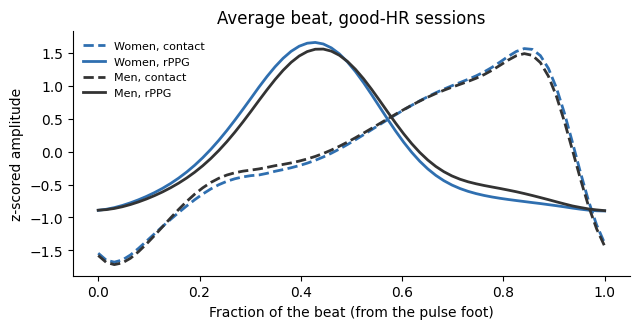

In [ ]:
def hr_est(x, fs=FS):
    y = bandpass(x, fs, .7, 3.5); f, Pw = welch(y, fs, nperseg=min(len(y), int(12 * fs)), nfft=8192)
    m = (f >= .7) & (f <= 3.5); sc = Pw[m] + .5 * np.interp(2 * f[m], f, Pw, right=0); return f[m][np.argmax(sc)]
def snr_db(x, f0, fs=FS):
    f, Pw = welch(bandpass(x, fs, .5, 4.5), fs, nperseg=min(len(x), int(12 * fs)), nfft=8192)
    sig = ((np.abs(f - f0) <= .1) | (np.abs(f - 2 * f0) <= .1)) & (f >= .6) & (f <= 4.); rng = (f >= .6) & (f <= 4.)
    return 10 * np.log10(Pw[sig].sum() / max(Pw[rng & ~sig].sum(), 1e-12))
def combine(a):
    snr = np.array([snr_db(ch, hr_est(ch)) for ch in a]); w = 10 ** (np.clip(np.nan_to_num(snr, nan=-20), -20, 20) / 10)
    x = (w[:, None] * a).sum(0) / w.sum(); return x / (x.std() + 1e-12), snr
MORPH_COLS = ['rise_frac', 'w25', 'w50', 'w75', 'max_slope_pos', 'slope_ratio', 'area_ratio', 'skew', 'kurt', 'apg_b_a', 'apg_late_a', 'h2_h1', 'h3_h1', 'h4_h1', 'consistency', 'kept_frac', 'beats_per_min']
def pulse_template(x, fs=FS, up=4, n=64):
    f0 = hr_est(x, fs); xu = resample_poly(x, up, 1); xn = resample_poly(bandpass(x, fs, .7, 3.5), up, 1); T = fs * up / f0
    pk, _ = find_peaks(xn, distance=max(1, int(.6 * T))); a, b = int(.45 * T), int(.55 * T)
    segs = np.array([xu[p - a:p + b] for p in pk if p - a >= 0 and p + b <= len(xu)])
    if len(segs) < 10: return None
    segs = (segs - segs.mean(1, keepdims=True)) / (segs.std(1, keepdims=True) + 1e-9); med = np.median(segs, 0)
    r = np.array([np.corrcoef(s, med)[0, 1] for s in segs]); keep = r > .5
    if keep.sum() < 10: keep = np.ones(len(segs), bool)
    tpl = segs[keep].mean(0); tpl = np.roll(tpl, -int(np.argmin(tpl[:int(.7 * len(tpl))])))     # start at the pulse foot
    t = np.interp(np.linspace(0, len(tpl) - 1, n), np.arange(len(tpl)), tpl); t = (t - t.mean()) / (t.std() + 1e-9)
    d1 = np.gradient(t); d2 = np.gradient(d1); pkp = int(np.argmax(t)); rng_ = t.max() - t.min(); base = t - t.min()
    ia = int(np.argmax(d2[:max(pkp, 2)])); ib = ia + int(np.argmin(d2[ia:max(pkp + 4, ia + 2)])); late = d2[pkp:int(.75 * n)]
    f, Pw = welch(x, fs, nperseg=min(len(x), int(12 * fs)), nfft=8192)
    h = [Pw[np.abs(f - k * f0) <= .08].sum() + 1e-12 for k in (1, 2, 3, 4)]
    feats = dict(rise_frac=pkp / n, w25=np.mean(t > t.min() + .75 * rng_), w50=np.mean(t > t.min() + .5 * rng_), w75=np.mean(t > t.min() + .25 * rng_),
                 max_slope_pos=np.argmax(d1) / n, slope_ratio=d1.max() / max(-d1.min(), 1e-9), area_ratio=base[:pkp + 1].sum() / max(base[pkp:].sum(), 1e-9),
                 skew=skew(t), kurt=kurtosis(t), apg_b_a=d2[ib] / max(abs(d2[ia]), 1e-9), apg_late_a=(late.max() if len(late) else np.nan) / max(abs(d2[ia]), 1e-9),
                 h2_h1=np.log10(h[1] / h[0]), h3_h1=np.log10(h[2] / h[0]), h4_h1=np.log10(h[3] / h[0]), consistency=r[keep].mean(), kept_frac=keep.mean(), beats_per_min=60 * f0)
    return feats, np.concatenate([t, d1]).astype(np.float32)
def session_shape(a):
    if a is None: return None
    try:
        x, snr = combine(a); out = pulse_template(x)
        return None if out is None else (out[0], out[1], snr)
    except Exception: return None
def contact_shape(a):
    if a is None: return None
    try: return pulse_template(a.astype(float))
    except Exception: return None
with ThreadPoolExecutor(4) as ex:
    RS = list(tqdm(ex.map(session_shape, SIG['pos4']), total=len(KEYS), desc='rPPG pulse shape'))
    CS = list(tqdm(ex.map(contact_shape, PPG_W), total=len(KEYS), desc='contact pulse shape'))
MORPH_R = pd.DataFrame([r[0] if r else {} for r in RS], columns=MORPH_COLS)
REGION_SNR = pd.DataFrame([r[2] if r else [np.nan] * 4 for r in RS], columns=[f'snr8_{r}' for r in REGIONS])
TPL_R = np.array([r[1] if r else np.full(128, np.nan, np.float32) for r in RS])
MORPH_C = pd.DataFrame([c[0] if c else {} for c in CS], columns=MORPH_COLS); TPL_C = np.array([c[1] if c else np.full(128, np.nan, np.float32) for c in CS])
print(f'Pulse templates: rPPG {MORPH_R.rise_frac.notna().mean():.1%} of sessions, contact {MORPH_C.rise_frac.notna().mean():.1%}')

good = ((D.rppg_hr - D.ppg_hr).abs() <= 5).values
def tpl_corr(a, b, max_shift=6):
    if np.isnan(a).any() or np.isnan(b).any(): return np.nan
    return max(np.corrcoef(a[:64], np.roll(b[:64], s))[0, 1] for s in range(-max_shift, max_shift + 1))
same = np.array([tpl_corr(TPL_R[i], TPL_C[i]) for i in range(len(KEYS))])
other = np.array([tpl_corr(TPL_R[i], TPL_C[j]) for i, j in zip(range(len(KEYS)), np.roll(np.arange(len(KEYS)), 7))])
print(f'Template beat correlation, rPPG vs contact: same session {np.nanmedian(same):.2f}, another person {np.nanmedian(other):.2f}; good-HR {np.nanmedian(same[good]):.2f}, failed-HR {np.nanmedian(same[~good]):.2f}')
rows = []
for c in MORPH_COLS:
    a, b = MORPH_R[c], MORPH_C[c]; m = a.notna() & b.notna()
    rows.append(dict(feature=c, rho_all=spearmanr(a[m], b[m])[0], rho_good_hr=spearmanr(a[m & good], b[m & good])[0]))
SHAPE_AGREE = pd.DataFrame(rows).round(3); SHAPE_AGREE.to_csv(f'{OUT}/pulse_shape_agreement.csv', index=False); display(SHAPE_AGREE)
TPL_AGREE = dict(same=float(np.nanmedian(same)), other=float(np.nanmedian(other)))
fig, ax = plt.subplots(figsize=(6.5, 3.4)); xs = np.linspace(0, 1, 64)
for lab, sel, col in (('Women', D.male.values == 0, BLUE), ('Men', D.male.values == 1, INK)):
    ax.plot(xs, np.nanmean(TPL_C[sel & good, :64], 0), color=col, lw=2, ls='--', label=f'{lab}, contact'); ax.plot(xs, np.nanmean(TPL_R[sel & good, :64], 0), color=col, lw=2, label=f'{lab}, rPPG')
ax.set(xlabel='Fraction of the beat (from the pulse foot)', ylabel='z-scored amplitude', title='Average beat, good-HR sessions'); ax.legend(frameon=False, fontsize=8); ax.spines[['top', 'right']].set_visible(False); plt.tight_layout(); plt.savefig(f'{OUT}/average_beat.png', dpi=150); plt.show()

## 4. Shared evaluation code
- Folds are drawn **per person**, so session-level, person-level and CNN models all use the same split in a repeat.
- Two decision rules are reported:
  - **Balanced rule**: class-weighted probability ≥ 0.5. Treats men and women equally. This was Week 8's accuracy.
  - **Accuracy rule**: the probability corrected back to the training share of men, then ≥ 0.5, i.e. pick the more likely sex. Nothing is tuned on test people. It raises accuracy, but male recall can fall sharply when the model is unsure, so read it with its recall columns.
- `acc gain` is accuracy (accuracy rule) minus always-female accuracy, with a bootstrap CI.

In [ ]:
def person_folds(r, labels, groups=None):
    f = np.zeros(len(PEOPLE), int)
    for k, (_, te) in enumerate(StratifiedGroupKFold(5, shuffle=True, random_state=r).split(np.zeros(len(PEOPLE)), labels, PEOPLE if groups is None else groups)): f[te] = k
    return f
def make_frame(y, p, pi, r):
    p = np.clip(np.nan_to_num(p, nan=.5), 1e-6, 1 - 1e-6); cal = p * pi / (p * pi + (1 - p) * (1 - pi))
    return pd.DataFrame(dict(y=y, p=p, cal=cal, const=pi, repeat=r), index=pd.Index(PEOPLE, name='id'))
def fast(y, p, cal, c):
    yb, h, hc = y.astype(bool), p >= .5, cal >= .5; tp, tn, fp, fn = (h & yb).sum(), (~h & ~yb).sum(), (h & ~yb).sum(), (~h & yb).sum(); den = np.sqrt(float((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn)))
    acc_c = (hc == yb).mean()
    return dict(auc=roc_auc_score(y, p), bal_acc=(tp / max(tp + fn, 1) + tn / max(tn + fp, 1)) / 2, mcc=(tp * tn - fp * fn) / den if den else 0.,
                brier_skill=100 * (1 - ((y - cal) ** 2).sum() / ((y - c) ** 2).sum()), acc_cal=acc_c, acc_gain=acc_c - max(y.mean(), 1 - y.mean()))
def score(f):
    rows, boots = [], []
    for r, d in f.groupby('repeat'):
        y, p, cal, c = d.y.values.astype(int), d.p.values, d.cal.values, d.const.values; h, hc = (p >= .5).astype(int), (cal >= .5).astype(int)
        rows.append(dict(**fast(y, p, cal, c), n_people=len(y), acc=(y == h).mean(), majority=max(y.mean(), 1 - y.mean()), recall_m=h[y == 1].mean(), recall_f=1 - h[y == 0].mean(),
                         recall_m_cal=hc[y == 1].mean(), recall_f_cal=1 - hc[y == 0].mean(), f1_m=f1_score(y, h, zero_division=0), ap=average_precision_score(y, p)))
        rg = np.random.default_rng(int(r))
        for _ in range(N_BOOT):
            ix = rg.integers(0, len(y), len(y))
            if 0 < y[ix].sum() < len(ix): boots.append(fast(y[ix], p[ix], cal[ix], c[ix]))
    res = pd.DataFrame(rows).mean().to_dict(); B = pd.DataFrame(boots); res['repeats'] = f.repeat.nunique()
    for k in ('auc', 'bal_acc', 'acc_cal', 'acc_gain'): res[k + '_lo'], res[k + '_hi'] = np.percentile(B[k], [2.5, 97.5])
    return res
RES, PRED, GROUP = {}, {}, {}
def record(name, f, group):
    PRED[name] = f; RES[name] = score(f); GROUP[name] = group; r = RES[name]
    print(f"{name:58s} AUC {r['auc']:.3f} [{r['auc_lo']:.3f}, {r['auc_hi']:.3f}]  bal.acc {r['bal_acc']:.3f}  acc(bal) {r['acc']:.3f}  acc(acc rule) {r['acc_cal']:.3f} [{r['acc_cal_lo']:.3f}, {r['acc_cal_hi']:.3f}]  recall M {r['recall_m']:.2f} F {r['recall_f']:.2f}")
def cv(name, fold_fn, group, labels=None, repeats=None, groups=None, cache=False):
    y = YP if labels is None else np.asarray(labels); reps = REPEATS if repeats is None else repeats
    path = Path(OUT)/'pred_cache'/(re.sub(r'\W+', '_', name) + f'_r{reps}_s{CNN_SEEDS}_e{EPOCHS}{"_quick" if QUICK else ""}.pkl')
    old = Path(V3)/'pred_cache'/path.name
    if cache and (path.exists() or old.exists()): record(name, pickle.load(open(path if path.exists() else old, 'rb')), group); return
    out = []
    for r in range(reps):
        fm = person_folds(r, y, groups); p, pi = np.full(len(y), np.nan), np.full(len(y), np.nan)
        for k in range(5):
            tr, te = np.where(fm != k)[0], np.where(fm == k)[0]; p[te] = fold_fn(tr, te, y, r, k); pi[te] = y[tr].mean()
        out.append(make_frame(y, p, pi, r))
    f = pd.concat(out)
    if cache: pickle.dump(f, open(path, 'wb'))
    record(name, f, group)
def to_person(ps, sess_idx, te):
    return pd.Series(ps).groupby(SESS_POS[sess_idx]).mean().reindex(te).values
def sk_session(make, X):
    X = np.asarray(X, float)
    def fn(tr, te, y, r, k):
        ys = y[SESS_POS]; a, b = np.where(np.isin(SESS_POS, tr))[0], np.where(np.isin(SESS_POS, te))[0]
        return to_person(make().fit(X[a], ys[a]).predict_proba(X[b])[:, 1], b, te)
    return fn
def sk_person(make, X):
    X = np.asarray(X, float)
    return lambda tr, te, y, r, k: make().fit(X[tr], y[tr]).predict_proba(X[te])[:, 1]
def LOG(C=.1): return lambda: make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), LogisticRegression(C=C, class_weight='balanced', max_iter=3000))
def HGB(): return make_pipeline(SimpleImputer(strategy='median'), HistGradientBoostingClassifier(max_iter=200, max_depth=3, learning_rate=.04, min_samples_leaf=15, l2_regularization=1., class_weight='balanced', random_state=0))
def ETR(): return make_pipeline(SimpleImputer(strategy='median'), ExtraTreesClassifier(500, min_samples_leaf=4, max_features='sqrt', class_weight='balanced_subsample', random_state=0, n_jobs=-1))
def SVM(): return make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), SVC(C=1., gamma='scale', class_weight='balanced', probability=True, random_state=0))

## 5. Split each signal into pulse-locked and pulse-removed parts
Short-time Fourier transform: 10 s windows, 0.5 s steps, 0.05 Hz bins. In each window the heart rate is found from the reference signal (contact PPG by default). The mask keeps bins within ±(0.10 + 0.03k) Hz of the k-th harmonic, k = 1–6, up to 8 Hz.

The table shows what share of each channel's power falls in the mask. Contact PPG should be mostly pulse; a low rPPG share means most of the rPPG signal is not heartbeat.

In [ ]:
from scipy.signal import stft, istft, medfilt
NPS, NOV, NFFT = 300, 285, 600
def hr_track(x):
    f, t, Z = stft(np.asarray(x, float), FS, nperseg=NPS, noverlap=NOV, nfft=NFFT); Pw = np.abs(Z) ** 2
    ii = np.where((f >= .7) & (f <= 3.5))[0]; sc = Pw[ii] + .5 * Pw[np.minimum(2 * ii, len(f) - 1)]
    return medfilt(f[ii][np.argmax(sc, 0)], 9)
def pulse_mask(f, f0, kmax=6):
    M = np.zeros((len(f), len(f0)), bool)
    for k in range(1, kmax + 1): M |= np.abs(f[:, None] - k * f0[None, :]) <= (.10 + .03 * k)
    return M & (f[:, None] <= 8.)
def fit_len(x, T):
    return x[..., :T] if x.shape[-1] >= T else np.concatenate([x, np.zeros(x.shape[:-1] + (T - x.shape[-1],), x.dtype)], -1)
def decompose(a, ref):
    # a: (channels, samples). ref: 1-D signal that sets the heart-rate track. Returns pulse-locked part, pulse-removed part, pulse power share per channel.
    T = a.shape[1]; f, t, Z = stft(a, FS, nperseg=NPS, noverlap=NOV, nfft=NFFT); f0 = hr_track(ref); n = Z.shape[-1]
    f0 = f0[:n] if len(f0) >= n else np.concatenate([f0, np.full(n - len(f0), f0[-1])]); M = pulse_mask(f, f0); Pw = np.abs(Z) ** 2
    share = (Pw * M).sum((-2, -1)) / (Pw.sum((-2, -1)) + 1e-12)
    xp = fit_len(istft(Z * M, FS, nperseg=NPS, noverlap=NOV, nfft=NFFT)[1], T); xr = fit_len(istft(Z * ~M, FS, nperseg=NPS, noverlap=NOV, nfft=NFFT)[1], T)
    return xp.astype(np.float32), xr.astype(np.float32), share
def phase_scramble(a, seed):
    # Same random phase for every channel: keeps each channel's power spectrum and the phase differences between channels, destroys beat shape.
    F = np.fft.rfft(a, axis=-1); ph = np.exp(1j * np.random.default_rng(seed).uniform(0, 2 * np.pi, F.shape[-1])); ph[0] = 1
    return np.fft.irfft(F * ph, a.shape[-1], axis=-1).astype(np.float32)
def rppg_ref(i): return combine(SIG['pos4'][i])[0]
def session_parts(i):
    a = SIG['multi12'][i]
    if a is None: return None
    ref = PPG_W[i] if (MASK_HR == 'contact' and PPG_W[i] is not None) else rppg_ref(i)
    xp, xr, share = decompose(a, ref); out = dict(pulse=xp, removed=xr, share=share, phase=phase_scramble(a, i))
    if PPG_W[i] is not None:
        cp, cr, cs = decompose(PPG_W[i][None].astype(float), PPG_W[i]); out.update(c_removed=cr, c_share=cs[0])
    if RUN_RC_VARIANTS and MASK_HR == 'contact':
        out['pulse_rhr'] = decompose(a[POS_IDX], rppg_ref(i))[0]
    return out
with ThreadPoolExecutor(4) as ex: PARTS = list(tqdm(ex.map(session_parts, range(len(KEYS))), total=len(KEYS), desc='pulse split'))
SIG['pulse12'] = [None if p is None else p['pulse'] for p in PARTS]; SIG['removed12'] = [None if p is None else p['removed'] for p in PARTS]; SIG['phase12'] = [None if p is None else p['phase'] for p in PARTS]
SIG['ppg_removed'] = [None if p is None or 'c_removed' not in p else p['c_removed'] for p in PARTS]
SIG['pos4_pulse_rhr'] = [None if p is None or 'pulse_rhr' not in p else p['pulse_rhr'] for p in PARTS] if (RUN_RC_VARIANTS and MASK_HR == 'contact') else [None if p is None else p['pulse'][POS_IDX] for p in PARTS]
for k in ('pulse12', 'removed12', 'phase12'): CH_GROUP[k] = 3
SHARE = np.array([np.full(12, np.nan) if p is None else p['share'] for p in PARTS]); C_SHARE = np.array([np.nan if p is None or 'c_share' not in p else p['c_share'] for p in PARTS]); del PARTS
ST = pd.DataFrame(SHARE, columns=CHANNELS)
tab = pd.DataFrame({'all sessions': ST.median(), 'women': ST[D.male.values == 0].median(), 'men': ST[D.male.values == 1].median()}).round(3)
tab.loc['contact PPG'] = [np.nanmedian(C_SHARE), np.nanmedian(C_SHARE[D.male.values == 0]), np.nanmedian(C_SHARE[D.male.values == 1])]
tab.to_csv(f'{OUT}/pulse_power_share.csv'); print(f'Pulse power share (median), mask from {MASK_HR} heart rate:'); display(tab)

pulse split:   0%|          | 0/1196 [00:00<?, ?it/s]

Pulse power share (median), mask from contact heart rate:


,all sessions,women,men
face_pos,0.406000,0.385000,0.443000
face_chrom,0.308000,0.298000,0.331000
face_green,0.106000,0.099000,0.117000
forehead_pos,0.300000,0.297000,0.310000
forehead_chrom,0.256000,0.252000,0.266000
forehead_green,0.107000,0.103000,0.116000
left_cheek_pos,0.266000,0.253000,0.292000
left_cheek_chrom,0.240000,0.232000,0.253000
left_cheek_green,0.107000,0.103000,0.116000
right_cheek_pos,0.266000,0.258000,0.285000


## 6. Person-level models
- Week 9 fusion part: gradient boosting on all rPPG tabular features (HRV, quality, SNR, pulse shape).
- **Physiology only**: HRV and pulse shape, without quality, SNR or consistency features, which can reflect appearance.
- **Pulse power share**: 12 numbers per session, how much of each channel is heartbeat. A pure quality measure.
- **Spectral statistics**: per channel band-power fractions, spectral flatness, kurtosis and pulse share. Describes the signal without its waveform.
- References: appearance (skin colour per region) and age + BMI.

In [ ]:
def per_person(frame):
    S = pd.DataFrame(np.asarray(frame, float), columns=list(frame.columns) if hasattr(frame, 'columns') else [f'v{i}' for i in range(np.asarray(frame).shape[1])])
    S['pid'], S['step'] = D.patient_id.values, D.step.values; cols = [c for c in S.columns if c not in ('pid', 'step')]
    b = S[S.step == 'before'].set_index('pid')[cols].reindex(PEOPLE); a = S[S.step == 'after'].set_index('pid')[cols].reindex(PEOPLE)
    return pd.concat([b.add_suffix('_b'), a.add_suffix('_a'), (a - b).add_suffix('_d')], axis=1)
def spectral_stats(i):
    raw = MULTI[i]
    if raw is None: return np.full(12 * 7, np.nan)
    f, Pw = welch(raw.astype(np.float32), FS, nperseg=600, axis=-1); tot = Pw[:, (f >= .3) & (f <= 12)].sum(1) + 1e-12
    bands = [np.log10(Pw[:, (f >= a) & (f < b)].sum(1) / tot + 1e-9) for a, b in ((.3, .7), (.7, 4), (4, 8), (8, 12))]
    m = (f >= .5) & (f <= 8); flat = np.exp(np.log(Pw[:, m] + 1e-12).mean(1)) / (Pw[:, m].mean(1) + 1e-12)
    return np.concatenate(bands + [flat, kurtosis(SIG['multi12'][i], axis=1), SHARE[i]])
STATS = pd.DataFrame([spectral_stats(i) for i in range(len(KEYS))], columns=[f'{s}_{c}' for s in ('p03', 'p07', 'p4', 'p8', 'flat', 'kurt', 'share') for c in CHANNELS])
APP_COLS = [f'{r}_{s}' for r in REGIONS for s in ('chroma_r', 'chroma_g', 'lum', 'lum_var')]
SHAPE_PHYS = [c for c in MORPH_COLS if c not in ('consistency', 'kept_frac')]
T_RALL = pd.concat([per_person(D[RPPG_TAB]), per_person(pd.concat([MORPH_R, REGION_SNR], axis=1))], axis=1)
T_PHYS = pd.concat([per_person(D[PHYS]), per_person(MORPH_R[SHAPE_PHYS])], axis=1)
T_APP = per_person(pd.concat([pd.DataFrame(APP, columns=APP_COLS), D[SKIN]], axis=1)); T_DEMO = P[['age', 'bmi']]
PERSON_R = 'Person HGB: all rPPG tabular'; APPEAR = 'Appearance: per-region skin colour (HGB)'; AGEBMI = 'Age + BMI (logistic)'
cv(PERSON_R, sk_person(HGB, T_RALL), 'rPPG, as Week 9')
cv('Person HGB: rPPG physiology only (no quality or SNR)', sk_person(HGB, T_PHYS), 'rPPG, pulse')
cv('Person HGB: pulse power share per channel', sk_person(HGB, per_person(ST)), 'rPPG, signal statistics')
cv('Person HGB: spectral statistics per channel', sk_person(HGB, per_person(STATS)), 'rPPG, signal statistics')
cv(APPEAR, sk_person(HGB, T_APP), 'Appearance')
cv(AGEBMI, sk_person(LOG(1.), T_DEMO), 'Not rPPG')
cv('Shuffled sex: person HGB, seed 0', sk_person(HGB, T_RALL), 'Control', labels=np.random.default_rng(0).permutation(YP), repeats=1)
cv('Shuffled sex: person HGB, seed 1', sk_person(HGB, T_RALL), 'Control', labels=np.random.default_rng(1).permutation(YP), repeats=1)

Person HGB: all rPPG tabular                               AUC 0.679 [0.621, 0.734]  bal.acc 0.641  acc(bal) 0.689  acc(acc rule) 0.717 [0.681, 0.753]  recall M 0.50 F 0.78
Person HGB: rPPG physiology only (no quality or SNR)       AUC 0.656 [0.600, 0.712]  bal.acc 0.619  acc(bal) 0.662  acc(acc rule) 0.703 [0.664, 0.741]  recall M 0.49 F 0.75
Person HGB: pulse power share per channel                  AUC 0.658 [0.602, 0.711]  bal.acc 0.598  acc(bal) 0.647  acc(acc rule) 0.685 [0.649, 0.722]  recall M 0.45 F 0.75
Person HGB: spectral statistics per channel                AUC 0.768 [0.729, 0.806]  bal.acc 0.682  acc(bal) 0.721  acc(acc rule) 0.724 [0.686, 0.759]  recall M 0.56 F 0.80
Appearance: per-region skin colour (HGB)                   AUC 0.762 [0.718, 0.802]  bal.acc 0.689  acc(bal) 0.719  acc(acc rule) 0.721 [0.682, 0.758]  recall M 0.60 F 0.78
Age + BMI (logistic)                                       AUC 0.698 [0.653, 0.742]  bal.acc 0.657  acc(bal) 0.688  acc(acc rule) 0.696

## 7. Random convolutions on each signal version
Features from each region's POS channel, concatenated (the Week 9 fusion part), then logistic regression.

Two checks that the split works:
- **Contact PPG with the pulse removed** should lose most of its sex information.
- **High vs low contact heart rate from pulse-removed rPPG** should be near chance. If not, the gaps left by the mask still reveal the heart rate, and pulse-removed results must be read with care.

In [ ]:
_KERN = {}
def kernels(L, seed=0):
    if (L, seed) not in _KERN:
        rg = np.random.default_rng(seed); nfft = 2 * L; ks, dil = [], []
        for _ in range(N_KERNELS):
            k = rg.normal(size=rg.choice([7, 9, 11])); k -= k.mean(); d = int(2 ** rg.uniform(0, np.log2((L - 1) / (len(k) - 1)) * .55)); kk = np.zeros((len(k) - 1) * d + 1); kk[::d] = k
            ks.append(np.fft.rfft(kk, nfft)); dil.append(len(kk))
        _KERN[(L, seed)] = (ks, dil)
    return _KERN[(L, seed)]
def rand_features(sig, win_s=20, n_win=6):
    L = int(FS * win_s); nfft = 2 * L; ks, dil = kernels(L); windows, owner = [], []
    for i, x in enumerate(sig):
        if x is None or len(x) < L: continue
        x = np.nan_to_num(np.asarray(x, np.float32))
        for s in np.linspace(0, len(x) - L, n_win).astype(int):
            w = x[s:s + L]; windows.append((w - w.mean()) / (w.std() + 1e-6)); owner.append(i)
    F = np.fft.rfft(np.stack(windows), nfft, axis=1); out = np.zeros((len(windows), 2 * N_KERNELS), np.float32)
    for j, (K, l) in enumerate(zip(ks, dil)):
        c = np.fft.irfft(F * K, nfft, axis=1)[:, l - 1:L]; out[:, 2 * j] = (c > 0).mean(1); out[:, 2 * j + 1] = c.max(1)
    return pd.DataFrame(out).groupby(np.array(owner)).mean().reindex(range(len(sig))).values
RC = lambda: make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), LogisticRegression(C=.001, class_weight='balanced', max_iter=3000))
RC_REGION = 'Random conv: 4 regions separately, 0.5-8 Hz'
def rc_regions(sig): return np.hstack([rand_features([None if a is None else a[j] for a in sig]) for j in range(len(POS_IDX))])
hr = D.groupby('patient_id').ppg_hr.mean().reindex(PEOPLE); HR_LAB = (hr > hr.median()).astype(int).values
RC_X = rc_regions(SIG['pos4']); cv(RC_REGION, sk_session(RC, RC_X), 'rPPG, as Week 9')
RCV = {}
if RUN_RC_VARIANTS:
    for k, lab in (('pulse12', 'pulse-locked'), ('removed12', 'pulse removed'), ('phase12', 'phase-scrambled')):
        RCV[k] = rc_regions([None if a is None else a[POS_IDX] for a in SIG[k]]); cv(f'Random conv: {lab}', sk_session(RC, RCV[k]), f'Attribution: {lab}')
    cv('Random conv: pulse-locked, rPPG heart rate (deployable)', sk_session(RC, rc_regions(SIG['pos4_pulse_rhr'])), 'Attribution: pulse-locked')
    CX = rand_features(PPG_W); CXR = rand_features([None if a is None else a[0] for a in SIG['ppg_removed']])
    cv('Random conv: contact PPG (ceiling)', sk_session(RC, CX), 'Contact')
    cv('Random conv: contact PPG, pulse removed (mask check)', sk_session(RC, CXR), 'Check')
    cv('Check: high contact HR from rPPG, full signal', sk_session(RC, RC_X), 'Check', labels=HR_LAB, repeats=1)
    cv('Check: high contact HR from rPPG, pulse removed', sk_session(RC, RCV['removed12']), 'Check', labels=HR_LAB, repeats=1)

Random conv: 4 regions separately, 0.5-8 Hz                AUC 0.779 [0.735, 0.820]  bal.acc 0.696  acc(bal) 0.734  acc(acc rule) 0.719 [0.681, 0.754]  recall M 0.58 F 0.81
Random conv: pulse-locked                                  AUC 0.733 [0.685, 0.780]  bal.acc 0.683  acc(bal) 0.715  acc(acc rule) 0.723 [0.688, 0.761]  recall M 0.59 F 0.78
Random conv: pulse removed                                 AUC 0.659 [0.611, 0.706]  bal.acc 0.594  acc(bal) 0.647  acc(acc rule) 0.673 [0.634, 0.709]  recall M 0.43 F 0.75
Random conv: phase-scrambled                               AUC 0.640 [0.591, 0.688]  bal.acc 0.599  acc(bal) 0.654  acc(acc rule) 0.692 [0.654, 0.729]  recall M 0.43 F 0.77
Random conv: pulse-locked, rPPG heart rate (deployable)    AUC 0.731 [0.684, 0.777]  bal.acc 0.673  acc(bal) 0.708  acc(acc rule) 0.716 [0.677, 0.754]  recall M 0.57 F 0.78
Random conv: contact PPG (ceiling)                         AUC 0.778 [0.731, 0.819]  bal.acc 0.701  acc(bal) 0.707  acc(acc rule) 0.731

## 8. CNN attribution variants
ResNet1D with Week 9's improved training. The reference row is the Week 9 primary CNN, reused from its saved predictions when found.

| Row | Input |
|---|---|
| Reference | 4 regions × POS/CHROM/green, 0.5–8 Hz |
| Pulse-locked | the same 12 channels, heartbeat part only |
| Pulse removed | the same 12 channels, heartbeat removed |
| Phase-scrambled | the same 12 channels, beat shape destroyed |
| Cheeks, POS only | 2 channels |
| Cheeks, CHROM + green only | 4 channels |
| Check | high vs low contact HR from pulse-removed signals |

In [ ]:
import torch, torch.nn as nn
DEV = torch.device('cuda' if torch.cuda.is_available() else 'cpu'); WIN = int(WIN_S * FS); print('device:', DEV)
if str(DEV) == 'cpu' and RUN_CNN: print('WARNING: no GPU. The CNN section will take many hours. Set RUN_CNN = False or change the runtime.')
def conv_blk(i, o, k=7): return nn.Sequential(nn.Conv1d(i, o, k, padding=k // 2), nn.BatchNorm1d(o), nn.ReLU(), nn.MaxPool1d(2))
class ResBlock(nn.Module):
    def __init__(self, i, o, stride=2, k=15):
        super().__init__()
        self.net = nn.Sequential(nn.Conv1d(i, o, k, stride=stride, padding=k // 2), nn.BatchNorm1d(o), nn.ReLU(), nn.Dropout(.1), nn.Conv1d(o, o, k, padding=k // 2), nn.BatchNorm1d(o))
        self.skip = nn.Sequential(nn.Conv1d(i, o, 1, stride=stride), nn.BatchNorm1d(o)); self.act = nn.ReLU()
    def forward(self, x): return self.act(self.net(x) + self.skip(x))
class Net(nn.Module):
    def __init__(self, in_ch):
        super().__init__()
        self.enc = nn.Sequential(nn.Conv1d(in_ch, 32, 15, stride=2, padding=7), nn.BatchNorm1d(32), nn.ReLU(), ResBlock(32, 32), ResBlock(32, 64), ResBlock(64, 64))
        self.head = nn.Sequential(nn.Dropout(.4), nn.Linear(64, 1))
    def forward(self, x): return self.head(self.enc(x).mean(-1)).squeeze(-1)

def zwin(x): return (x - x.mean(-1, keepdims=True)) / (x.std(-1, keepdims=True) + 1e-6)
def sample(items, sig, flag, rng, aug=False, ch_group=1):
    C = sig[items[0]].shape[0]; X = np.empty((len(items), C + 1, WIN), np.float32); n_groups = C // ch_group
    for n, i in enumerate(items):
        T = sig[i].shape[1]; L = min(T, int(round(WIN * rng.uniform(.92, 1.08)))) if aug else WIN; st = rng.integers(0, T - L + 1); seg = sig[i][:, st:st + L].astype(np.float32)
        if L != WIN:
            x = np.linspace(0, L - 1, WIN); i0 = np.floor(x).astype(int); w = (x - i0).astype(np.float32); i1 = np.minimum(i0 + 1, L - 1); seg = seg[:, i0] * (1 - w) + seg[:, i1] * w
        seg = zwin(seg)
        if aug:
            seg = seg + rng.normal(0, rng.uniform(0, .3), seg.shape).astype(np.float32)
            if n_groups > 1 and rng.random() < .3: g = rng.integers(n_groups); seg[g * ch_group:(g + 1) * ch_group] = 0
        X[n, :C] = seg; X[n, C] = flag[i]
    return X
@torch.no_grad()
def predict(model, sig, flag, idx, stride_s=10):
    model.eval(); out = np.full(len(idx), np.nan); stride = int(stride_s * FS)
    for n, i in enumerate(idx):
        if sig[i] is None or sig[i].shape[1] < WIN: continue
        st = np.arange(0, sig[i].shape[1] - WIN + 1, stride); C = sig[i].shape[0]; X = np.empty((len(st), C + 1, WIN), np.float32)
        for m, s in enumerate(st): X[m, :C] = zwin(sig[i][:, s:s + WIN]); X[m, C] = flag[i]
        out[n] = float(model(torch.from_numpy(X).to(DEV)).mean().cpu())
    return out
def fit_predict(sig, flag, y, ids, tr, te, seed, improved=True, ch_group=1):
    # sig: list of (channels, samples) arrays or None. Returns P(male) for sessions te.
    rng = np.random.default_rng(seed); torch.manual_seed(seed); people = pd.Series(y[tr], index=ids[tr]).groupby(level=0).first()
    val_ids = set(np.concatenate([rng.choice(people.index[people == c], max(3, int(.1 * (people == c).sum())), replace=False) for c in (0, 1)]))
    usable = [i for i in tr if sig[i] is not None and sig[i].shape[1] >= WIN]; fit = np.array([i for i in usable if ids[i] not in val_ids]); val = np.array([i for i in usable if ids[i] in val_ids])
    model = Net(sig[fit[0]].shape[0] + 1).to(DEV); pos = float(y[fit].mean()); pw = torch.tensor((1 - pos) / pos, dtype=torch.float32, device=DEV)
    opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-3)
    n_steps = EPOCHS * int(np.ceil(len(fit) * WIN_PER_SESSION / BATCH)); sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, max(n_steps, 1)) if improved else None
    smooth, stride = (.05, 5) if improved else (0., 10); best, state, bad = -1., None, 0
    for ep in range(EPOCHS):
        model.train(); order = rng.permutation(np.repeat(fit, WIN_PER_SESSION))
        for b in range(0, len(order), BATCH):
            ch = order[b:b + BATCH]
            if len(ch) < 2: continue
            X = torch.from_numpy(sample(ch, sig, flag, rng, improved, ch_group)).to(DEV); t = torch.from_numpy((y[ch] * (1 - 2 * smooth) + smooth).astype(np.float32)).to(DEV)
            loss = nn.functional.binary_cross_entropy_with_logits(model(X), t, pos_weight=pw); opt.zero_grad(); loss.backward(); opt.step()
            if sched is not None: sched.step()
        pv = predict(model, sig, flag, val, stride); f = pd.DataFrame(dict(i=ids[val], y=y[val], p=pv)).dropna().groupby('i').mean(); auc = roc_auc_score(f.y.astype(int), f.p)
        if auc > best + 1e-4: best, bad, state = auc, 0, {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= PATIENCE: break
    model.load_state_dict(state); return 1 / (1 + np.exp(-predict(model, sig, flag, te, stride)))

# Self-test on planted data: pulses at two frequencies must be separable. Stops the notebook if the CNN code is broken.
_r = np.random.default_rng(0); _y = np.repeat([0, 1], 80); _ids = np.arange(160); _t = np.arange(900) / FS
_s = [np.stack([np.sin(2 * np.pi * (1. + .5 * c) * _t + _r.uniform(0, 6)) + _r.normal(0, .3, 900) for _ in range(3)]).astype(np.float32) for c in _y]
_ep = EPOCHS; EPOCHS = 10; _o = _r.permutation(160)
for _imp in (False, True):
    _p = fit_predict(_s, np.zeros(160, np.float32), _y, _ids, _o[:120], _o[120:], 0, _imp, 3); _au = roc_auc_score(_y[_o[120:]], _p)
    print(f'self-test, improved={_imp}: AUC {_au:.2f}'); assert _au > .75, 'CNN self-test failed'
EPOCHS = _ep

device: cuda
self-test, improved=False: AUC 1.00
self-test, improved=True: AUC 1.00


In [ ]:
def cnn_fn(key, improved=True, seeds=None, chans=None, group=None):
    seeds = CNN_SEEDS if seeds is None else seeds; grp = CH_GROUP.get(key, 1) if group is None else group
    def fn(tr, te, y, r, k):
        sig = SIG[key] if chans is None else [None if a is None else a[chans] for a in SIG[key]]
        ys = y[SESS_POS]; a, b = np.where(np.isin(SESS_POS, tr))[0], np.where(np.isin(SESS_POS, te))[0]; lg = []
        for s in range(seeds):
            p = np.clip(fit_predict(sig, FLAG, ys, SESS_IDS, a, b, 1000 * r + 10 * k + s, improved, grp), 1e-6, 1 - 1e-6); lg.append(np.log(p / (1 - p)))
        return to_person(1 / (1 + np.exp(-np.nanmean(lg, 0))), b, te)
    return fn
PRIMARY = 'CNN primary: 4 regions x POS/CHROM/green'
CHEEK_POS = [CHANNELS.index(f'{r}_pos') for r in ('left_cheek', 'right_cheek')]; CHEEK_CG = [CHANNELS.index(f'{r}_{a}') for r in ('left_cheek', 'right_cheek') for a in ('chrom', 'green')]
if RUN_CNN:
    cv('Control: CNN predicts high contact HR', cnn_fn('pos4', False, 1), 'Control', labels=HR_LAB, repeats=1, cache=True)
    cv(PRIMARY, cnn_fn('multi12', True), 'rPPG, as Week 9', repeats=CNN_REPEATS, cache=True)
    cv('CNN: pulse-locked', cnn_fn('pulse12'), 'Attribution: pulse-locked', repeats=VAR_REPEATS, cache=True)
    cv('CNN: pulse removed', cnn_fn('removed12'), 'Attribution: pulse removed', repeats=VAR_REPEATS, cache=True)
    cv('CNN: phase-scrambled', cnn_fn('phase12'), 'Attribution: phase-scrambled', repeats=VAR_REPEATS, cache=True)
    cv('CNN: cheeks, POS only', cnn_fn('multi12', chans=CHEEK_POS, group=1), 'Cheek test', repeats=VAR_REPEATS, cache=True)
    cv('CNN: cheeks, CHROM + green only', cnn_fn('multi12', chans=CHEEK_CG, group=2), 'Cheek test', repeats=VAR_REPEATS, cache=True)
    cv('Check: CNN predicts high contact HR from pulse-removed signals', cnn_fn('removed12', True, 1), 'Check', labels=HR_LAB, repeats=1, cache=True)
else:
    print('RUN_CNN = False: CNN rows skipped.')

Control: CNN predicts high contact HR                      AUC 0.981 [0.972, 0.989]  bal.acc 0.927  acc(bal) 0.926  acc(acc rule) 0.931 [0.910, 0.952]  recall M 0.94 F 0.91
CNN primary: 4 regions x POS/CHROM/green                   AUC 0.816 [0.770, 0.861]  bal.acc 0.739  acc(bal) 0.768  acc(acc rule) 0.754 [0.717, 0.791]  recall M 0.65 F 0.83
CNN: pulse-locked                                          AUC 0.824 [0.790, 0.854]  bal.acc 0.746  acc(bal) 0.761  acc(acc rule) 0.746 [0.714, 0.783]  recall M 0.70 F 0.79
CNN: pulse removed                                         AUC 0.799 [0.758, 0.831]  bal.acc 0.725  acc(bal) 0.692  acc(acc rule) 0.732 [0.694, 0.761]  recall M 0.82 F 0.63
CNN: phase-scrambled                                       AUC 0.738 [0.700, 0.778]  bal.acc 0.649  acc(bal) 0.635  acc(acc rule) 0.741 [0.709, 0.774]  recall M 0.69 F 0.61
CNN: cheeks, POS only                                      AUC 0.669 [0.625, 0.707]  bal.acc 0.611  acc(bal) 0.692  acc(acc rule) 0.681

## 9. Fusion and stacking
- **Week 9 primary fusion**, recomputed: CNN + random conv + person HGB, equal weights.
- **Pulse-locked fusion**: CNN and random conv on pulse-locked signals + physiology-only features. The best estimate of what the heartbeat alone gives (diagnostic when the mask uses contact HR).
- **Pulse-removed fusion**: CNN and random conv on pulse-removed signals.
- **Stacked**: a logistic regression on the branch scores, trained on the other four-fifths of people in each repeat. Exploratory.

In [ ]:
def fuse(name, parts, group):
    parts = [p for p in parts if p in PRED]
    if len(parts) < 2: print(f'{name}: skipped, needs 2+ parts'); return
    reps = sorted(set.intersection(*[set(PRED[p].repeat.unique()) for p in parts])); out = []
    for r in reps:
        fr = [PRED[p][PRED[p].repeat == r] for p in parts]; base = fr[0].copy(); pi = base.const.values
        lg = np.mean([np.log(np.clip(f.reindex(base.index).p.values, 1e-6, 1 - 1e-6) / (1 - np.clip(f.reindex(base.index).p.values, 1e-6, 1 - 1e-6))) for f in fr], axis=0)
        base['p'] = 1 / (1 + np.exp(-lg)); base['cal'] = base.p * pi / (base.p * pi + (1 - base.p) * (1 - pi)); out.append(base)
    record(name, pd.concat(out), group)
def stack(name, parts, group):
    parts = [p for p in parts if p in PRED]
    if len(parts) < 2: print(f'{name}: skipped'); return
    reps = sorted(set.intersection(*[set(PRED[p].repeat.unique()) for p in parts])); out = []
    for r in reps:
        fr = [PRED[p][PRED[p].repeat == r] for p in parts]; base = fr[0].copy(); y = base.y.values.astype(int)
        X = np.column_stack([np.log(np.clip(f.reindex(base.index).p.values, 1e-6, 1 - 1e-6) / (1 - np.clip(f.reindex(base.index).p.values, 1e-6, 1 - 1e-6))) for f in fr]); p = np.zeros(len(y))
        for tr, te in StratifiedKFold(5, shuffle=True, random_state=100 + r).split(X, y):
            p[te] = make_pipeline(StandardScaler(), LogisticRegression(C=1., class_weight='balanced', max_iter=2000)).fit(X[tr], y[tr]).predict_proba(X[te])[:, 1]
        pi = base.const.values; base['p'] = p; base['cal'] = p * pi / (p * pi + (1 - p) * (1 - pi)); out.append(base)
    record(name, pd.concat(out), group)
W9 = [PRIMARY, RC_REGION, PERSON_R]
fuse('Fusion: Week 9 primary (rPPG only)', W9, 'Fusion')
fuse('Fusion: pulse-locked (CNN + random conv + physiology)', ['CNN: pulse-locked', 'Random conv: pulse-locked', 'Person HGB: rPPG physiology only (no quality or SNR)'], 'Fusion')
fuse('Fusion: pulse removed (CNN + random conv)', ['CNN: pulse removed', 'Random conv: pulse removed'], 'Fusion')
fuse('Fusion: Week 9 primary + appearance', W9 + [APPEAR], 'Fusion, with non-rPPG')
stack('Stacked: rPPG branches', W9 + ['CNN: pulse-locked', 'Person HGB: spectral statistics per channel'], 'Stacked')
stack('Stacked: rPPG branches + appearance + age/BMI', W9 + ['CNN: pulse-locked', 'Person HGB: spectral statistics per channel', APPEAR, AGEBMI], 'Stacked, with non-rPPG')

Fusion: Week 9 primary (rPPG only)                         AUC 0.824 [0.784, 0.858]  bal.acc 0.736  acc(bal) 0.781  acc(acc rule) 0.745 [0.709, 0.778]  recall M 0.60 F 0.87
Fusion: pulse-locked (CNN + random conv + physiology)      AUC 0.791 [0.752, 0.830]  bal.acc 0.708  acc(bal) 0.753  acc(acc rule) 0.737 [0.702, 0.776]  recall M 0.57 F 0.84
Fusion: pulse removed (CNN + random conv)                  AUC 0.798 [0.755, 0.834]  bal.acc 0.716  acc(bal) 0.712  acc(acc rule) 0.734 [0.699, 0.768]  recall M 0.72 F 0.71
Fusion: Week 9 primary + appearance                        AUC 0.855 [0.819, 0.884]  bal.acc 0.759  acc(bal) 0.807  acc(acc rule) 0.745 [0.711, 0.779]  recall M 0.61 F 0.90
Stacked: rPPG branches                                     AUC 0.859 [0.827, 0.885]  bal.acc 0.773  acc(bal) 0.774  acc(acc rule) 0.799 [0.769, 0.829]  recall M 0.77 F 0.78
Stacked: rPPG branches + appearance + age/BMI              AUC 0.873 [0.843, 0.899]  bal.acc 0.798  acc(bal) 0.799  acc(acc rule) 0.821

## 10. Appearance and age/BMI checks, and accuracy
- **Appearance-stratified AUC**: people are grouped into fifths by their appearance-model score, and men are compared with women only inside each group. If a model mostly copies appearance, this AUC falls towards 0.5.
- **Added value**: does the model's score improve a cross-fitted logistic model that already has the appearance score (or age + BMI)?
- **Paired AUC differences** on the same bootstrap people.
- **Accuracy with a chosen threshold**: for each person, the threshold that maximises accuracy (or balanced accuracy) is chosen on the other four-fifths of people's out-of-fold scores.

In [ ]:
def logit_of(name):
    p = PRED[name].groupby('id').p.mean().reindex(PEOPLE).clip(1e-6, 1 - 1e-6); return np.log(p / (1 - p)).values
def strata_of(name): return pd.qcut(PRED[name].groupby('id').p.mean().reindex(PEOPLE), 5, labels=False, duplicates='drop').values
def strat_auc(name, s):
    f = PRED[name].groupby('id')[['y', 'p']].mean().reindex(PEOPLE); y, p = f.y.values.astype(int), f.p.values
    def calc(ix):
        tot, w = 0., 0
        for g in np.unique(s):
            m = ix[s[ix] == g]; yy = y[m]
            if yy.sum() >= 3 and (1 - yy).sum() >= 3: tot += roc_auc_score(yy, p[m]) * len(m); w += len(m)
        return tot / w
    rg = np.random.default_rng(3); return calc(np.arange(len(y))), *np.percentile([calc(rg.integers(0, len(y), len(y))) for _ in range(500)], [2.5, 97.5])
def added_value(name, base):
    y = YP; A = np.asarray(base, float).reshape(len(y), -1); B = np.column_stack([A, logit_of(name)]); pa, pb = np.zeros(len(y)), np.zeros(len(y))
    for tr, te in StratifiedKFold(5, shuffle=True, random_state=0).split(A, y):
        for X, o in ((A, pa), (B, pb)): o[te] = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), LogisticRegression(C=1., class_weight='balanced', max_iter=2000)).fit(X[tr], y[tr]).predict_proba(X[te])[:, 1]
    rg = np.random.default_rng(5); ds = []
    for _ in range(1000):
        ix = rg.integers(0, len(y), len(y))
        if 0 < y[ix].sum() < len(ix): ds.append(roc_auc_score(y[ix], pb[ix]) - roc_auc_score(y[ix], pa[ix]))
    return roc_auc_score(y, pb) - roc_auc_score(y, pa), *np.percentile(ds, [2.5, 97.5])
S_APP, S_AGE = strata_of(APPEAR), strata_of(AGEBMI)
rows = []
for n in [k for k in RES if not GROUP[k].startswith(('Control', 'Check', 'Appearance', 'Not rPPG', 'Contact')) and 'non-rPPG' not in GROUP[k]]:
    a, b = strat_auc(n, S_APP), strat_auc(n, S_AGE); va, vb = added_value(n, logit_of(APPEAR)), added_value(n, P[['age', 'bmi']].values)
    rows.append(dict(model=n, auc=RES[n]['auc'], auc_within_appearance=a[0], app_lo=a[1], app_hi=a[2], gain_over_appearance=va[0], ga_lo=va[1], ga_hi=va[2],
                     auc_within_age_bmi=b[0], gain_over_age_bmi=vb[0], gb_lo=vb[1], gb_hi=vb[2]))
CHECK = pd.DataFrame(rows).set_index('model').round(3); CHECK.to_csv(f'{OUT}/appearance_age_checks.csv'); pd.set_option('display.width', 250, 'display.max_columns', 40); display(CHECK)

def delta_auc(a, b):
    reps = sorted(set(PRED[a].repeat) & set(PRED[b].repeat)); pts, vals = [], []
    for r in reps:
        x = PRED[a][PRED[a].repeat == r]; z = PRED[b][PRED[b].repeat == r].reindex(x.index); y, pa, pb = x.y.values.astype(int), x.p.values, z.p.values; rg = np.random.default_rng(1000 + int(r))
        pts.append(roc_auc_score(y, pa) - roc_auc_score(y, pb))
        for _ in range(N_BOOT):
            ix = rg.integers(0, len(y), len(y))
            if 0 < y[ix].sum() < len(ix): vals.append(roc_auc_score(y[ix], pa[ix]) - roc_auc_score(y[ix], pb[ix]))
    return dict(diff=np.mean(pts), lo=np.percentile(vals, 2.5), hi=np.percentile(vals, 97.5))
pairs = [('CNN: pulse removed', PRIMARY), ('CNN: pulse-locked', PRIMARY), ('CNN: phase-scrambled', PRIMARY), ('CNN: cheeks, CHROM + green only', 'CNN: cheeks, POS only'),
         ('Random conv: pulse removed', RC_REGION), ('Random conv: pulse-locked', RC_REGION), ('Random conv: phase-scrambled', RC_REGION),
         ('Fusion: pulse-locked (CNN + random conv + physiology)', AGEBMI), ('Fusion: Week 9 primary (rPPG only)', APPEAR), ('Stacked: rPPG branches', 'Fusion: Week 9 primary (rPPG only)')]
GAINS = pd.DataFrame({f'{a}  minus  {b}': delta_auc(a, b) for a, b in pairs if a in PRED and b in PRED}).T.round(3); GAINS.to_csv(f'{OUT}/paired_auc_differences.csv'); display(GAINS)

def tuned(name, objective='acc'):
    out = []
    for r, d in PRED[name].groupby('repeat'):
        y, p = d.y.values.astype(int), d.p.values; h = np.zeros(len(y), bool)
        for tr, te in StratifiedKFold(5, shuffle=True, random_state=int(r)).split(p, y):
            c = np.quantile(p[tr], np.linspace(.02, .98, 97)); yt, pt = y[tr], p[tr]
            sc = [((pt >= t) == yt).mean() if objective == 'acc' else ((pt[yt == 1] >= t).mean() + (pt[yt == 0] < t).mean()) / 2 for t in c]; h[te] = p[te] >= c[int(np.argmax(sc))]
        out.append(dict(acc=(h == y).mean(), recall_m=h[y == 1].mean(), recall_f=(~h[y == 0]).mean()))
    return pd.DataFrame(out).mean()
key = [n for n in ['Fusion: Week 9 primary (rPPG only)', 'Stacked: rPPG branches', 'Fusion: pulse-locked (CNN + random conv + physiology)', PRIMARY, 'CNN: pulse-locked', 'Fusion: Week 9 primary + appearance', 'Stacked: rPPG branches + appearance + age/BMI', AGEBMI] if n in PRED]
ACC = pd.DataFrame({n: pd.concat([tuned(n, 'acc').add_prefix('max-accuracy '), tuned(n, 'bal').add_prefix('balanced ')]) for n in key}).T.round(3)
ACC.insert(0, 'always-female', MAJ); ACC.to_csv(f'{OUT}/accuracy_tuned_threshold.csv'); display(ACC)

,auc,auc_within_appearance,app_lo,app_hi,gain_over_appearance,ga_lo,ga_hi,auc_within_age_bmi,gain_over_age_bmi,gb_lo,gb_hi
model,,,,,,,,,,,
Person HGB: all rPPG tabular,0.679,0.682,0.629,0.740,0.035,0.012,0.058,0.648,0.049,0.014,0.084
Person HGB: rPPG physiology only (no quality or SNR),0.656,0.676,0.622,0.727,0.032,0.011,0.053,0.625,0.037,0.003,0.072
Person HGB: pulse power share per channel,0.658,0.678,0.625,0.735,0.030,0.010,0.050,0.658,0.045,0.010,0.079
Person HGB: spectral statistics per channel,0.768,0.715,0.657,0.769,0.060,0.032,0.089,0.763,0.112,0.071,0.152
"Random conv: 4 regions separately, 0.5-8 Hz",0.779,0.737,0.681,0.793,0.062,0.037,0.088,0.754,0.102,0.063,0.140
Random conv: pulse-locked,0.733,0.727,0.677,0.775,0.047,0.025,0.071,0.717,0.074,0.037,0.110
Random conv: pulse removed,0.659,0.634,0.579,0.695,0.022,0.005,0.039,0.644,0.028,-0.005,0.059
Random conv: phase-scrambled,0.640,0.612,0.552,0.670,0.013,-0.002,0.028,0.603,0.016,-0.016,0.047
"Random conv: pulse-locked, rPPG heart rate (deployable)",0.731,0.719,0.664,0.771,0.047,0.023,0.071,0.699,0.070,0.033,0.106


,diff,lo,hi
CNN: pulse removed minus CNN primary: 4 regions x POS/CHROM/green,-0.000,-0.036,0.041
CNN: pulse-locked minus CNN primary: 4 regions x POS/CHROM/green,0.024,-0.006,0.057
CNN: phase-scrambled minus CNN primary: 4 regions x POS/CHROM/green,-0.061,-0.103,-0.019
"CNN: cheeks, CHROM + green only minus CNN: cheeks, POS only",0.038,-0.007,0.087
"Random conv: pulse removed minus Random conv: 4 regions separately, 0.5-8 Hz",-0.120,-0.166,-0.072
"Random conv: pulse-locked minus Random conv: 4 regions separately, 0.5-8 Hz",-0.045,-0.085,-0.005
"Random conv: phase-scrambled minus Random conv: 4 regions separately, 0.5-8 Hz",-0.138,-0.185,-0.090
Fusion: pulse-locked (CNN + random conv + physiology) minus Age + BMI (logistic),0.097,0.053,0.143
Fusion: Week 9 primary (rPPG only) minus Appearance: per-region skin colour (HGB),0.069,0.021,0.119
Stacked: rPPG branches minus Fusion: Week 9 primary (rPPG only),0.031,0.013,0.047


,always-female,max-accuracy acc,max-accuracy recall_m,max-accuracy recall_f,balanced acc,balanced recall_m,balanced recall_f
Fusion: Week 9 primary (rPPG only),0.665552,0.786,0.578,0.891,0.777,0.638,0.847
Stacked: rPPG branches,0.665552,0.804,0.700,0.857,0.784,0.755,0.799
Fusion: pulse-locked (CNN + random conv + physiology),0.665552,0.744,0.485,0.874,0.731,0.665,0.764
CNN primary: 4 regions x POS/CHROM/green,0.665552,0.767,0.592,0.854,0.755,0.718,0.774
CNN: pulse-locked,0.665552,0.778,0.610,0.862,0.719,0.750,0.704
Fusion: Week 9 primary + appearance,0.665552,0.811,0.607,0.913,0.779,0.802,0.768
Stacked: rPPG branches + appearance + age/BMI,0.665552,0.821,0.700,0.882,0.801,0.755,0.824
Age + BMI (logistic),0.665552,0.690,0.446,0.812,0.690,0.527,0.772


## 11. Results

,Group,Repeats,AUC,lo,hi,Bal acc,Acc (balanced rule),Recall M,Recall F,Acc (accuracy rule),MCC,PR-AUC,Brier skill %
Person HGB: all rPPG tabular,"rPPG, as Week 9",5.0,0.679,0.621,0.734,0.641,0.689,0.497,0.785,0.717,0.288,0.567,9.625
Person HGB: rPPG physiology only (no quality or SNR),"rPPG, pulse",5.0,0.656,0.600,0.712,0.619,0.662,0.490,0.749,0.703,0.240,0.540,6.315
Person HGB: pulse power share per channel,"rPPG, signal statistics",5.0,0.658,0.602,0.711,0.598,0.647,0.448,0.748,0.685,0.199,0.480,3.945
Person HGB: spectral statistics per channel,"rPPG, signal statistics",5.0,0.768,0.729,0.806,0.682,0.721,0.563,0.801,0.724,0.367,0.614,17.412
Appearance: per-region skin colour (HGB),Appearance,5.0,0.762,0.718,0.802,0.689,0.719,0.598,0.780,0.721,0.375,0.603,17.023
Age + BMI (logistic),Not rPPG,5.0,0.698,0.653,0.742,0.657,0.688,0.563,0.751,0.696,0.310,0.514,8.783
"Shuffled sex: person HGB, seed 0",Control,1.0,0.569,0.523,0.620,0.534,0.579,0.400,0.668,0.632,0.067,0.372,-4.524
"Shuffled sex: person HGB, seed 1",Control,1.0,0.527,0.477,0.585,0.524,0.584,0.345,0.704,0.627,0.049,0.351,-9.308
"Random conv: 4 regions separately, 0.5-8 Hz","rPPG, as Week 9",5.0,0.779,0.735,0.820,0.696,0.734,0.579,0.813,0.719,0.397,0.622,18.084
Random conv: pulse-locked,Attribution: pulse-locked,5.0,0.733,0.685,0.780,0.683,0.715,0.587,0.780,0.723,0.365,0.597,15.523


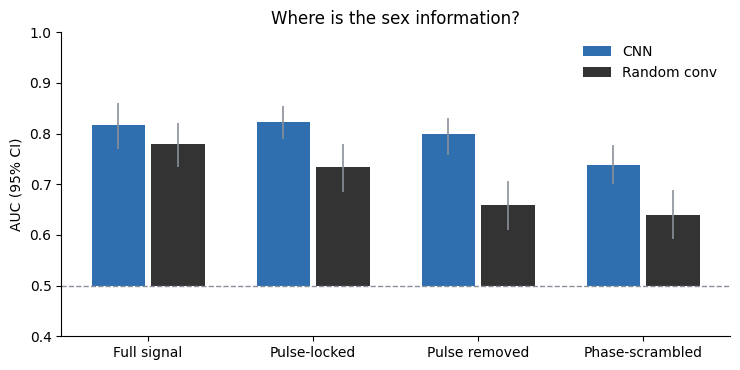

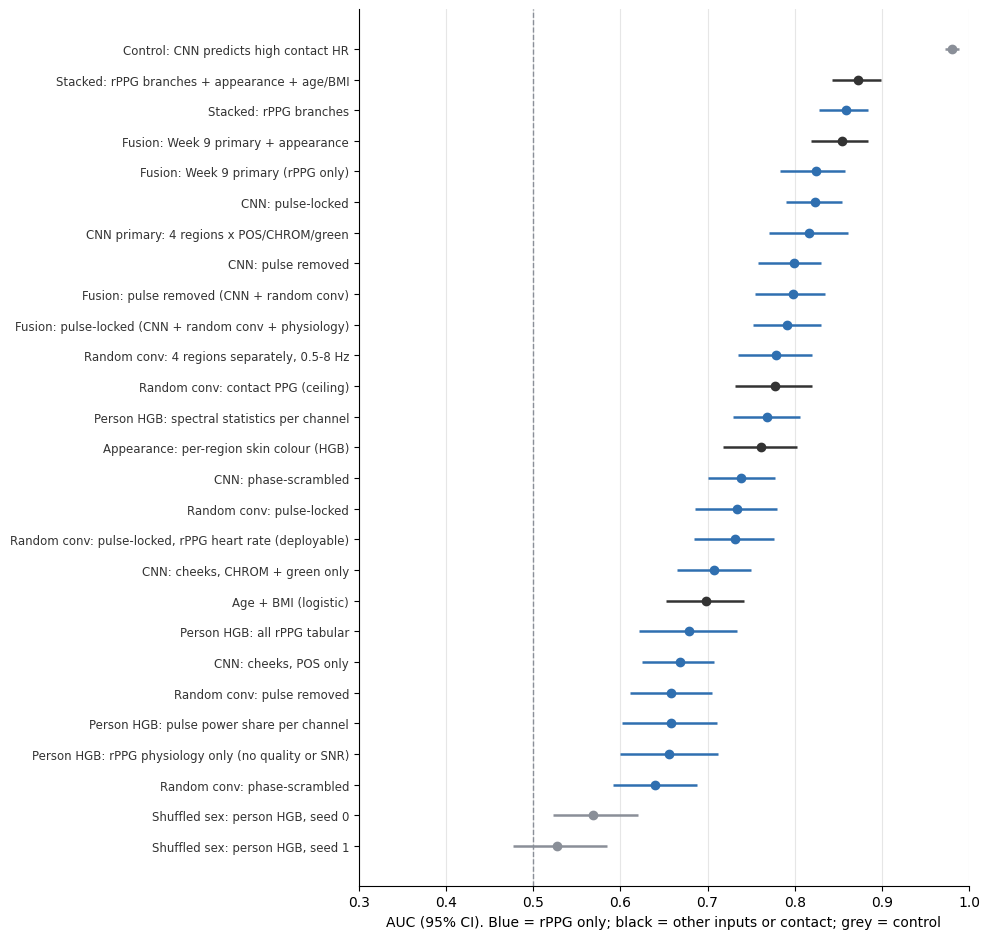

In [ ]:
T = pd.DataFrame(RES).T; T.insert(0, 'group', pd.Series(GROUP)); T.to_csv(f'{OUT}/sex_v4_metrics.csv')
cols = ['group', 'repeats', 'auc', 'auc_lo', 'auc_hi', 'bal_acc', 'acc', 'recall_m', 'recall_f', 'acc_cal', 'mcc', 'ap', 'brier_skill']
V = T[cols].copy(); V[cols[1:]] = V[cols[1:]].astype(float).round(3)
V.columns = ['Group', 'Repeats', 'AUC', 'lo', 'hi', 'Bal acc', 'Acc (balanced rule)', 'Recall M', 'Recall F', 'Acc (accuracy rule)', 'MCC', 'PR-AUC', 'Brier skill %']; display(V)

att = []
for fam, ref, names in (('CNN', PRIMARY, ['CNN: pulse-locked', 'CNN: pulse removed', 'CNN: phase-scrambled']), ('Random conv', RC_REGION, ['Random conv: pulse-locked', 'Random conv: pulse removed', 'Random conv: phase-scrambled'])):
    for lab, n in zip(['Full signal', 'Pulse-locked', 'Pulse removed', 'Phase-scrambled'], [ref] + names):
        if n in RES: att.append((fam, lab, RES[n]['auc'], RES[n]['auc_lo'], RES[n]['auc_hi']))
ATT = pd.DataFrame(att, columns=['model', 'signal', 'auc', 'lo', 'hi'])
if len(ATT):
    fig, ax = plt.subplots(figsize=(7.5, 3.8)); labs = ['Full signal', 'Pulse-locked', 'Pulse removed', 'Phase-scrambled']; w = .36
    for j, (fam, colr) in enumerate((('CNN', BLUE), ('Random conv', INK))):
        d = ATT[ATT.model == fam].set_index('signal').reindex(labs); x = np.arange(len(labs)) + (j - .5) * w
        ax.bar(x, d.auc - .5, w * .9, bottom=.5, color=colr, label=fam); ax.errorbar(x, d.auc, yerr=[d.auc - d.lo, d.hi - d.auc], fmt='none', ecolor=GREY, lw=1.2)
    ax.axhline(.5, color=GREY, ls='--', lw=1); ax.set_xticks(range(len(labs)), labs); ax.set(ylabel='AUC (95% CI)', ylim=(.4, 1), title='Where is the sex information?')
    ax.legend(frameon=False); ax.spines[['top', 'right']].set_visible(False); plt.tight_layout(); plt.savefig(f'{OUT}/attribution.png', dpi=150); plt.show()

S = T[~T.group.isin(['Check'])].astype({'auc': float, 'auc_lo': float, 'auc_hi': float}).sort_values('auc')
col = lambda g: GREY if g.startswith('Control') else INK if g in ('Not rPPG', 'Appearance', 'Contact', 'Fusion, with non-rPPG', 'Stacked, with non-rPPG') else BLUE
fig, ax = plt.subplots(figsize=(10, max(4, .3 * len(S) + 1.4)))
for i, (n, r) in enumerate(S.iterrows()): ax.errorbar(r.auc, i, xerr=[[r.auc - r.auc_lo], [r.auc_hi - r.auc]], fmt='o', ms=6, lw=1.8, color=col(r.group))
ax.axvline(.5, color=GREY, ls='--', lw=1); ax.set_yticks(range(len(S)), S.index, color=INK, fontsize=8.5)
ax.set(xlabel='AUC (95% CI). Blue = rPPG only; black = other inputs or contact; grey = control', xlim=(.3, 1)); ax.spines[['top', 'right']].set_visible(False); ax.grid(axis='x', color='#E6E6E6', lw=.8); ax.set_axisbelow(True)
plt.tight_layout(); plt.savefig(f'{OUT}/sex_v4_forest.png', dpi=150); plt.show()

## 12. Automatic verdict
Rules are fixed in code. "Close" means within 0.05 AUC.

In [ ]:
g = lambda n, k='auc': RES[n][k] if n in RES else np.nan
print(f"Pulse power share, median over rPPG channels: {np.nanmedian(SHARE):.2f} (contact PPG {np.nanmedian(C_SHARE):.2f}); mask from {MASK_HR} heart rate")
for fam, ref, pul, rem, pha in (('CNN', PRIMARY, 'CNN: pulse-locked', 'CNN: pulse removed', 'CNN: phase-scrambled'), ('Random conv', RC_REGION, 'Random conv: pulse-locked', 'Random conv: pulse removed', 'Random conv: phase-scrambled')):
    if not all(n in RES for n in (ref, pul, rem)): continue
    full, p_, r_, ph = g(ref), g(pul), g(rem), g(pha)
    print(f"\n{fam}: full {full:.3f} | pulse-locked {p_:.3f} | pulse removed {r_:.3f} [{g(rem, 'auc_lo'):.3f}, {g(rem, 'auc_hi'):.3f}] | phase-scrambled {ph:.3f}")
    if g(ref, 'auc_lo') <= .55: print('  -> The full-signal model is not clearly above chance, so this test cannot attribute anything.'); continue
    if g(rem, 'auc_lo') > .6 and r_ >= full - .05: print('  -> Most sex information is OUTSIDE the heartbeat (appearance, motion or noise).')
    elif p_ >= full - .05 and r_ < .6: print('  -> Sex information is mainly IN the heartbeat.')
    else: print('  -> Mixed: both the heartbeat and other content contribute.')
    if ph == ph: print('  -> Phase scrambling keeps the AUC: the model uses power levels, not beat shape.' if ph >= full - .05 else '  -> Phase scrambling lowers the AUC: beat shape or timing matters.')
cg, cp = 'CNN: cheeks, CHROM + green only', 'CNN: cheeks, POS only'
if cg in RES and cp in RES: print(f"\nCheeks: CHROM + green {g(cg):.3f} vs POS {g(cp):.3f}")
print(f"\nPulse-power share alone: {g('Person HGB: pulse power share per channel'):.3f}; spectral statistics alone: {g('Person HGB: spectral statistics per channel'):.3f}; appearance: {g(APPEAR):.3f}")
for n in ('Fusion: Week 9 primary (rPPG only)', 'Fusion: pulse-locked (CNN + random conv + physiology)', 'Stacked: rPPG branches'):
    if n in CHECK.index: c = CHECK.loc[n]; print(f"{n}: AUC {c.auc:.3f}; within appearance groups {c.auc_within_appearance:.3f}; gain over appearance {c.gain_over_appearance:+.3f} [{c.ga_lo:+.3f}, {c.ga_hi:+.3f}]")
print()
for n, lim in (('Random conv: contact PPG, pulse removed (mask check)', None), ('Check: high contact HR from rPPG, pulse removed', .7), ('Check: CNN predicts high contact HR from pulse-removed signals', .7)):
    if n in RES:
        print(f"{n}: AUC {g(n):.3f}")
        if lim and g(n) > lim: print('  WARNING: heart rate is still recoverable after removing the pulse, so pulse-removed AUCs may include some pulse information.')
if 'Random conv: contact PPG, pulse removed (mask check)' in RES and 'Random conv: contact PPG (ceiling)' in RES:
    d = g('Random conv: contact PPG (ceiling)') - g('Random conv: contact PPG, pulse removed (mask check)')
    if g('Random conv: contact PPG (ceiling)') > .6: print(f"Contact PPG loses {d:.3f} AUC when its pulse is removed" + (' (mask works).' if d > .1 else ' -- WARNING: small drop, check the mask.'))
for n in [k for k in RES if k.startswith('Shuffled')] + ['Control: CNN predicts high contact HR']:
    if n in RES: print(f"{n}: {g(n):.3f}")

Pulse power share, median over rPPG channels: 0.23 (contact PPG 0.84); mask from contact heart rate

CNN: full 0.816 | pulse-locked 0.824 | pulse removed 0.799 [0.758, 0.831] | phase-scrambled 0.738
  -> Most sex information is OUTSIDE the heartbeat (appearance, motion or noise).
  -> Phase scrambling lowers the AUC: beat shape or timing matters.

Random conv: full 0.779 | pulse-locked 0.733 | pulse removed 0.659 [0.611, 0.706] | phase-scrambled 0.640
  -> Mixed: both the heartbeat and other content contribute.
  -> Phase scrambling lowers the AUC: beat shape or timing matters.

Cheeks: CHROM + green 0.707 vs POS 0.669

Pulse-power share alone: 0.658; spectral statistics alone: 0.768; appearance: 0.762
Fusion: Week 9 primary (rPPG only): AUC 0.824; within appearance groups 0.804; gain over appearance +0.094 [+0.063, +0.123]
Fusion: pulse-locked (CNN + random conv + physiology): AUC 0.791; within appearance groups 0.772; gain over appearance +0.073 [+0.044, +0.103]
Stacked: rPPG branche